# Do EDA à redução de dimensionalidade
## Laboratório em aula · Palmer Penguins

**Machine Learning · Insper**

Um percurso completo: olhar os dados coluna a coluna, depois aos pares, separar treino de
teste, montar um pipeline que trata ausentes e escalas **sem vazar informação**, e projetar
tudo em duas dimensões com **PCA, t-SNE e UMAP** — comparando os três com o mesmo critério.

**Como usar.** Cada etapa termina com um valor de verificação. Rode a célula, confira o
número, e só então siga. Se não bater, o erro está antes — não adianta continuar.

| | |
|---|---|
| Pinguins | 344 |
| Colunas de entrada | 6 (4 numéricas + 2 categóricas) |
| Valores ausentes | 19, de duas causas diferentes |
| Métodos comparados | 3 |

> ##### Antes de começar
> Rode a célula abaixo uma única vez. O `umap-learn` não vem pré-instalado no Colab e
> leva cerca de um minuto. Os demais pacotes já estão lá.


In [1]:
# instala o UMAP (≈1 min) — os outros pacotes já vêm no Colab
!pip install umap-learn -q

import warnings; warnings.filterwarnings("ignore")
from IPython.display import display
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 110
print("pronto")

pronto


# Reconhecer o terreno

**Etapa 0 · 10 min**

O laboratório inteiro usa **Palmer Penguins**: 344 pinguins medidos em três ilhas do arquipélago Palmer, na Antártida. Foi escolhido por quatro razões, e cada uma vai importar em algum momento.

| Característica | Onde ela aparece |
|---|---|
| **Tipos misturados** | Quatro medidas numéricas e duas colunas categóricas de texto. Sem isso não há `ColumnTransformer` para montar. |
| **Valores ausentes** | 19 células vazias, em duas situações bem diferentes. A etapa 4 trata as duas. |
| **Estrutura visível** | As três espécies formam grupos que a redução consegue separar — você *verá* o resultado, em vez de acreditar nele. |
| **Pequeno** | 344 linhas: t-SNE e UMAP rodam em menos de um segundo. Dá para errar e refazer sem perder a aula. |

In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
df  = pd.read_csv(URL)

display(df.shape)   # (344, 7)
display(df.dtypes)   # 4 float64, 3 object
df.head()

(344, 7)

species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
dtype: object

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


**Verificação:** 344 linhas e 7 colunas. Se vier diferente, pare aqui.

> ##### Antes de qualquer gráfico, responda três perguntas
>
> 1. **O que é uma linha?** Um pinguim medido uma vez. Não é uma ilha, nem uma espécie, nem uma expedição — e isso decide o que significa cada média que você calcular.
> 2. **Quais colunas são categóricas?** Aqui é fácil, porque são texto. Nem sempre é: `Pclass` no Titanic é 1, 2, 3 e é categórica; CEP é número e é categórico. **O tipo do pandas não decide isso — você decide.**
> 3. **Qual coluna é o rótulo?** `species`. Ela *não* entra na redução: serve só para colorir os gráficos no fim e conferir se o que apareceu faz sentido.

# Univariada: uma coluna de cada vez

**Etapa 1 · 25 min**

#### 1a · As quatro numéricas

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.00,342.00,342.00,342.00
mean,43.92,17.15,200.92,4201.75
std,5.46,1.97,14.06,801.95
min,32.10,13.10,172.00,2700.00
25%,39.22,15.60,190.00,3550.00
50%,44.45,17.30,197.00,4050.00
75%,48.50,18.70,213.00,4750.00
max,59.60,21.50,231.00,6300.00


array([[<Axes: title={'center': 'bill_length_mm'}>,
        <Axes: title={'center': 'bill_depth_mm'}>],
       [<Axes: title={'center': 'flipper_length_mm'}>,
        <Axes: title={'center': 'body_mass_g'}>]], dtype=object)

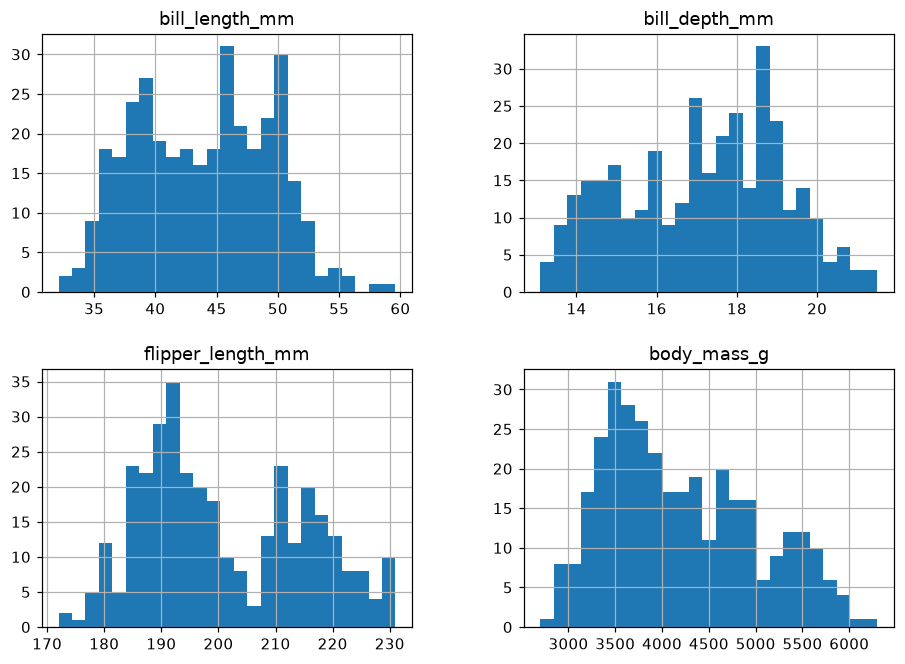

In [3]:
NUM = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
CAT = ["island", "sex"]

display(df[NUM].describe().round(2))

df[NUM].hist(bins=25, figsize=(10, 7), layout=(2, 2))

In [4]:
df.loc[0]

species                 Adelie
island               Torgersen
bill_length_mm            39.1
bill_depth_mm             18.7
flipper_length_mm        181.0
body_mass_g             3750.0
sex                       MALE
Name: 0, dtype: object

| coluna | média | dp | mín | máx | assimetria |
|---|---|---|---|---|---|
| `bill_length_mm` | 43,92 | 5,46 | 32,1 | 59,6 | +0,053 |
| `bill_depth_mm` | 17,15 | 1,97 | 13,1 | 21,5 | −0,143 |
| `flipper_length_mm` | 200,92 | 14,06 | 172 | 231 | +0,346 |
| `body_mass_g` | 4201,75 | 801,95 | 2700 | 6300 | +0,470 |

> ##### Duas leituras, e uma pergunta para a turma
>
> **As escalas são incomparáveis.** O desvio padrão de `body_mass_g` é 802 e o de `bill_depth_mm` é 1,97 — **407 vezes menor**. Numa distância euclidiana sem padronizar, a massa decidiria tudo sozinha. Guarde: é o argumento da etapa 4.
>
> **Nenhuma assimetria é preocupante** — todas entre −0,15 e +0,47. Não vamos precisar de `log` aqui, ao contrário do `Fare` do Titanic.
>
> **A pergunta:** olhe o histograma de `flipper_length_mm`. Ele tem *duas corcovas*. O que isso costuma indicar, e o que você faria para investigar?

#### 1b · As duas categóricas, e os ausentes

In [5]:
# investigar a bimodalidade de flipper_length_mm: cruzar com as categóricas disponíveis
display(df.groupby("species")["flipper_length_mm"].agg(["mean", "std", "count"]).round(1))
df.groupby("sex")["flipper_length_mm"].agg(["mean", "std", "count"]).round(1)

,mean,std,count
species,,,
Adelie,190.0,6.5,151
Chinstrap,195.8,7.1,68
Gentoo,217.2,6.5,123


,mean,std,count
sex,,,
FEMALE,197.4,12.5,165
MALE,204.5,14.5,168


**Resposta:** Duas corcovas num histograma geralmente indicam uma mistura de subpopulações diferentes escondida dentro da coluna — o jeito de investigar é cruzar a variável numérica com cada coluna categórica disponível, uma de cada vez, e comparar médias/desvios. Fazendo isso aqui: por **espécie**, Adelie fica em 190,0 mm (dp 6,5, n=151) e Chinstrap em 195,8 mm (dp 7,1, n=68) — bem próximas uma da outra — enquanto Gentoo salta para 217,2 mm (dp 6,5, n=123), quase 20 mm acima das outras duas. É essa separação que gera as duas corcovas: um pico menor por volta de 190–196 mm (Adelie + Chinstrap misturadas) e um pico maior perto de 217 mm (Gentoo isolada). Testei também por **sexo** (fêmeas 197,4±12,5 mm, machos 204,5±14,5 mm): a diferença existe, mas as duas distribuições se sobrepõem demais para abrir dois picos por si só. Conclusão: a bimodalidade vem da espécie (e, por tabela de contingência, da ilha — Gentoo só existe em Biscoe), não do sexo.

In [6]:
for c in CAT + ["species"]:
    print(df[c].value_counts(dropna=False), "\n")

display(df.isna().sum())   # bill_* e body_mass: 2 cada; sex: 11
df.isna().any(axis=1).sum()           # 11 linhas afetadas ao todo

island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64 

sex
MALE      168
FEMALE    165
NaN        11
Name: count, dtype: int64 

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64 



species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

np.int64(11)

**Verificação:** `species` = Adelie 152, Gentoo 124, Chinstrap 68. `island` = Biscoe 168, Dream 124, Torgersen 52. `sex` = MALE 168, FEMALE 165, e **11 ausentes**.

> ##### Os ausentes não são todos do mesmo tipo — e o tratamento não pode ser o mesmo
>
> **Duas linhas** têm as quatro medidas corporais faltando de uma vez. É um pinguim que entrou na planilha sem ter sido medido — provavelmente registro incompleto de campo.
>
> **Nove linhas** têm todas as medidas, mas o sexo em branco. Determinar o sexo de um pinguim exige análise de sangue, e nem todos foram testados. **É ausência por procedimento, não por descuido.**
>
> Na etapa 4 as duas receberão estratégias diferentes: mediana para as numéricas, moda para a categórica. Repare que isso não é escolha de gosto — decorre de *por que* o dado falta.

# Bivariada e correlação: duas colunas por vez

**Etapa 2 · 20 min**

#### 2a · Numérica × numérica

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.000,-0.235,0.656,0.595
bill_depth_mm,-0.235,1.000,-0.584,-0.472
flipper_length_mm,0.656,-0.584,1.000,0.871
body_mass_g,0.595,-0.472,0.871,1.000


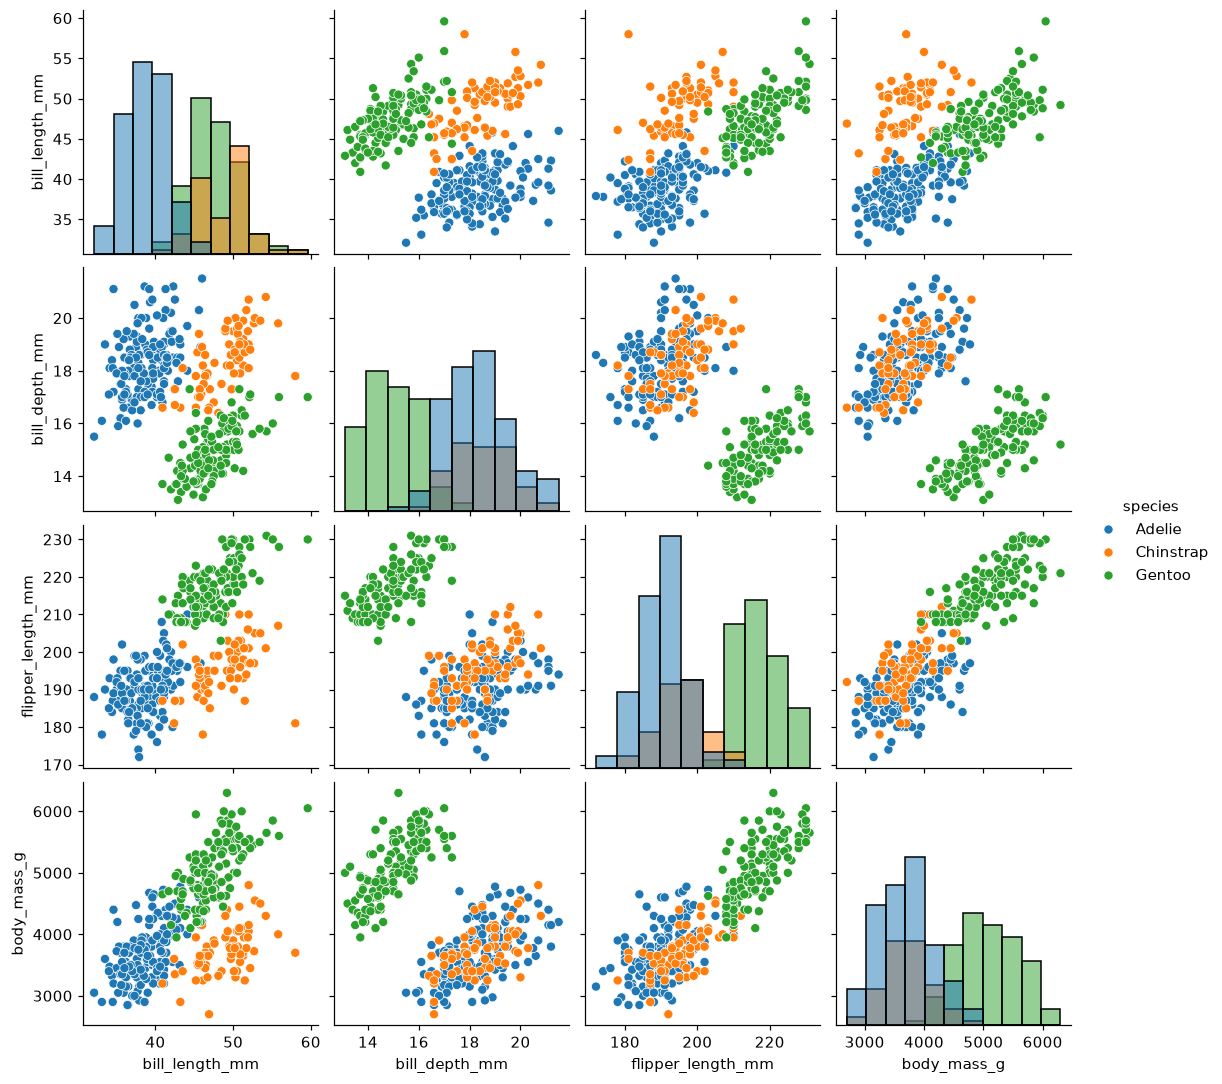

In [7]:
display(df[NUM].corr().round(3))
sns.pairplot(df, vars=NUM, hue="species", diag_kind="hist")

|  | comp. bico | prof. bico | nadadeira | massa |
|---|---|---|---|---|
| comprimento do bico | 1,000 | −0,235 | 0,656 | 0,595 |
| profundidade do bico | −0,235 | 1,000 | −0,584 | −0,472 |
| nadadeira | 0,656 | −0,584 | 1,000 | **0,871** |
| massa | 0,595 | −0,472 | **0,871** | 1,000 |

**Nadadeira e massa correlacionam 0,871** — uma explica 76% da variação da outra. São duas medidas de "pinguim grande". Isso é colinearidade, e vai reaparecer na etapa 5 como uma componente principal dominante.

> ##### O achado da etapa: uma correlação que troca de sinal
>
> Comprimento e profundidade do bico têm **r = −0,235**: bico mais comprido seria bico mais raso. Agora calcule dentro de cada espécie:

In [8]:
df.groupby("species")[["bill_length_mm", "bill_depth_mm"]].corr().round(3)

bill_length_mm  bill_depth_mm
species                                                
Adelie    bill_length_mm           1.000          0.391
          bill_depth_mm            0.391          1.000
Chinstrap bill_length_mm           1.000          0.654
          bill_depth_mm            0.654          1.000
Gentoo    bill_length_mm           1.000          0.643
          bill_depth_mm            0.643          1.000

| grupo | r entre comprimento e profundidade |
|---|---|
| *todos os 344 juntos* | **−0,235** |
| só Adelie (n = 152) | +0,391 |
| só Chinstrap (n = 68) | +0,654 |
| só Gentoo (n = 124) | +0,643 |

O sinal **inverte**. Dentro de cada espécie, bico mais comprido é bico mais fundo — o que faz sentido biológico. Agregando as três, aparece o contrário, porque Gentoo tem bico comprido *e* raso e puxa a nuvem inteira.

É o **paradoxo de Simpson**, e a lição é dura: **uma correlação calculada sobre grupos misturados pode dizer o oposto do que vale dentro de cada grupo.** Sempre que houver uma variável de agrupamento à mão, calcule a correlação também dentro dela.

#### 2b · Categórica × numérica

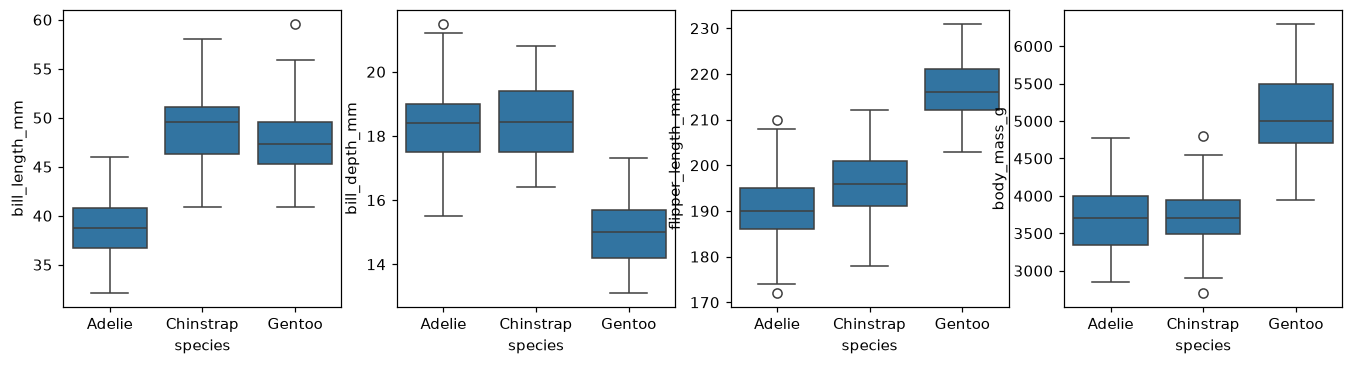

In [9]:
df.groupby("species")[NUM].mean().round(1)

fig, ax = plt.subplots(1, 4, figsize=(15, 3.5))
for a, c in zip(ax, NUM):
    sns.boxplot(data=df, x="species", y=c, ax=a)

| espécie | comp. bico | prof. bico | nadadeira | massa |
|---|---|---|---|---|
| Adelie | 38,8 | 18,3 | 190,0 | 3.701 |
| Chinstrap | 48,8 | 18,4 | 195,8 | 3.733 |
| Gentoo | 47,5 | 15,0 | 217,2 | 5.076 |

**Nenhuma coluna sozinha separa as três.** O comprimento do bico distingue Adelie das outras duas, mas confunde Chinstrap com Gentoo. A profundidade separa Gentoo, mas junta Adelie e Chinstrap. **É preciso combinar** — e é exatamente isso que a redução de dimensionalidade vai fazer.

#### 2c · Categórica × categórica

In [10]:
pd.crosstab(df.island, df.species)

species,Adelie,Chinstrap,Gentoo
island,,,
Biscoe,44,0,124
Dream,56,68,0
Torgersen,52,0,0


| ilha | Adelie | Chinstrap | Gentoo |
|---|---|---|---|
| Biscoe | 44 | 0 | 124 |
| Dream | 56 | 68 | 0 |
| Torgersen | 52 | 0 | 0 |

> ##### Pare aqui e discuta: a ilha quase entrega a resposta
>
> Os zeros não são acaso. **Chinstrap só existe em Dream. Gentoo só existe em Biscoe. Torgersen só tem Adelie.** Chutando a espécie majoritária de cada ilha, você acerta **70,9%** — sabendo apenas onde o pinguim estava.
>
> Isso levanta uma pergunta que *não* tem resposta técnica: **a ilha deve entrar na análise?**
>
> - **Se a pergunta é "as medidas corporais distinguem as espécies?"** — não. Incluir a ilha faz o mapa parecer bem-sucedido por um motivo que não é o que você quis testar.
> - **Se a pergunta é "consigo identificar a espécie de um pinguim novo?"** — sim, é informação legítima e disponível.
>
> Vamos **incluir** a ilha, e voltar a este ponto na etapa 7 para medir o quanto ela contribuiu. Anote sua expectativa agora.

# Separar treino e teste — antes de qualquer transformação

**Etapa 3 · 10 min**

Até aqui olhamos os dados inteiros, e está certo: **o EDA pode ver tudo**. A partir do momento em que se vai *aprender um parâmetro* — uma mediana, uma média, um desvio —, a regra muda.

**Resposta (anotando a expectativa antes de seguir):** Minha expectativa é que a ilha contribua pouco para a separação real das espécies nos mapas de PCA/t-SNE/UMAP, porque ela está confundida com a espécie por construção do próprio dataset (cada ilha tem uma composição de espécies quase fixa — ver a tabela de contingência acima), não porque carregue informação morfológica própria sobre o pinguim. Minha previsão: quando olharmos os *loadings* da PC1 na etapa 5, as colunas de `island` (e de `sex`) vão pesar bem menos que as quatro medidas numéricas — chuto algo abaixo de 0,2 em valor absoluto, contra pesos de 0,4–0,6 nas numéricas.

In [11]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["species"])      # o rótulo sai: não entra na redução
y = df.species

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=0, stratify=y)

display(X_tr.shape, X_te.shape)   # (258, 6) (86, 6)
display(y_tr.value_counts(normalize=True).round(3))
y_te.value_counts(normalize=True).round(3)

(258, 6)

(86, 6)

species
Adelie       0.442
Gentoo       0.360
Chinstrap    0.198
Name: proportion, dtype: float64

species
Adelie       0.442
Gentoo       0.360
Chinstrap    0.198
Name: proportion, dtype: float64

**Verificação:** 258 e 86 linhas. E as proporções batem *exatamente* nos dois conjuntos — Adelie 0,442, Gentoo 0,360, Chinstrap 0,198 — porque usamos `stratify=y`.

> ##### Por que estratificar aqui
>
> Chinstrap é 20% da amostra: são 68 pinguins, dos quais 17 caem no teste. Sem `stratify`, um sorteio azarado poderia deixar o teste com 10 ou com 25 — e qualquer conclusão sobre essa espécie ficaria refém do sorteio. Com estratificação, a proporção é a mesma nos dois lados por construção.
>
> **Quando o rótulo não entra no modelo, ainda vale estratificar?** Vale. Aqui a espécie não participa da redução, mas será usada para *avaliar* os mapas — e a avaliação precisa de todas as classes representadas nas duas partes.

# O pipeline: transformar sem vazar

**Etapa 4 · 25 min**

Quatro colunas numéricas com ausentes e escalas incompatíveis; duas categóricas de texto, uma delas também com ausentes. Cada grupo precisa de um tratamento próprio, e todos os parâmetros têm de ser aprendidos **só no treino**. É exatamente o que o `ColumnTransformer` faz.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

pipe_num = Pipeline([
    ("imp", SimpleImputer(strategy="median")),      # 2 linhas sem medidas
    ("esc", StandardScaler()),                       # 802 vs 1,97 de desvio
])
pipe_cat = Pipeline([
    ("imp", SimpleImputer(strategy="most_frequent")),   # 11 sexos em branco
    ("cod", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

prep = ColumnTransformer([("num", pipe_num, NUM),
                          ("cat", pipe_cat, CAT)])

Z_tr = prep.fit_transform(X_tr)     # aprende E transforma
Z_te = prep.transform(X_te)         # SÓ transforma

display(Z_tr.shape, Z_te.shape)   # (258, 9) (86, 9)
prep.get_feature_names_out()

(258, 9)

(86, 9)

array(['num__bill_length_mm', 'num__bill_depth_mm',
       'num__flipper_length_mm', 'num__body_mass_g', 'cat__island_Biscoe',
       'cat__island_Dream', 'cat__island_Torgersen', 'cat__sex_FEMALE',
       'cat__sex_MALE'], dtype=object)

**Verificação:** 9 colunas — 4 numéricas + 3 de `island` + 2 de `sex`. Zero `NaN` nos dois conjuntos.

> ##### Três coisas para conferir, e o que cada uma prova

In [13]:
import numpy as np
display(np.isnan(Z_tr).sum(), np.isnan(Z_te).sum())   # (0, 0)
display(np.abs(Z_tr[:, :4].mean(axis=0)).max())   # 0.0
display(Z_te[:, :4].mean(axis=0).round(3))   # [0.052 0.16 -0.002 0.089]
prep.named_transformers_["num"].named_steps["imp"].statistics_
# [44.5  17.3  197.  4000.]  <- medianas aprendidas NO TREINO

np.int64(0)

np.int64(0)

np.float64(7.857624972734635e-16)

array([ 0.052,  0.16 , -0.002,  0.089])

array([  44.5,   17.3,  197. , 4000. ])

- **Zero ausentes** nos dois lados: a imputação funcionou, e funcionou no teste com os valores do treino.
- **Média zero no treino, mas não no teste.** Os 0,052 e 0,16 não são defeito — são a *prova* de que o escalonador não viu o teste. Se a média do teste desse exatamente zero, haveria vazamento.
- **A mediana de `body_mass_g` é 4.000 no treino**, contra 4.050 no conjunto inteiro. Diferença pequena, e é justamente por ser pequena que o erro de ajustar na base toda passa despercebido.

> ##### Por que `sparse_output=False` e `handle_unknown="ignore"`?
>
> **Resposta honesta: neste dataset, nenhum dos dois faz diferença.** Estão ali por hábito defensivo, e vale saber contra o quê. **`sparse_output=False`** pede ao codificador uma matriz densa em vez de esparsa. Aqui é redundante **`handle_unknown="ignore"`** decide o que fazer quando o `transform` encontra uma categoria que não existia no `fit`. Sem ele, o padrão é `"error"` e o pipeline lança `ValueError: Found unknown categories`. Com ele, a linha recebe zeros em todas as colunas daquele bloco — a resposta honesta de "não vi isto no treino".
>
> Aqui também nunca dispara: testando **200 divisões diferentes**, nenhuma deixou uma categoria fora do treino. Faz sentido, porque a menor delas — Torgersen — tem 52 linhas. Mas basta uma categoria rara para o cenário mudar: no material sobre normalização, o deck `T` do Titanic tem **um único passageiro**, e sem este parâmetro o pipeline quebra em produção por causa de uma linha.
>
> **A lição não é decorar os parâmetros**, e sim reconhecer que os dois protegem contra situações que *este* dataset não tem e o próximo pode ter.

> ##### Uma armadilha que só aparece porque temos categóricas
>
> As 9 colunas de saída não são 9 direções independentes. As três de `island` somam 1 em toda linha; as duas de `sex` também. São **duas dependências lineares exatas**, e você vai vê-las na etapa 5 como **dois autovalores iguais a zero**.
>
> Para **modelos lineares com intercepto** isso é um defeito real: a matriz de projeto fica singular e os coeficientes ficam indeterminados. A solução usual é `drop="first"`, que descarta uma categoria de cada bloco. Modelos regularizados — Ridge, Lasso — e modelos baseados em árvores não se incomodam.
>
> **Para os nossos três métodos, a dependência não atrapalha** — o PCA simplesmente devolve dois autovalores nulos, e t-SNE e UMAP trabalham com distâncias, que continuam bem definidas. **Mas usar `drop="first"` aqui teria um efeito colateral geométrico**, e ele é fácil de ver com três ilhas:
>
> | distância entre | one-hot completo | `drop="first"` |
> |---|---|---|
> | Biscoe ↔ Dream | 1,414 | 1,000 |
> | Biscoe ↔ Torgersen | 1,414 | 1,000 |
> | Dream ↔ Torgersen | 1,414 | 1,414 |
>
> *Biscoe é a categoria descartada, e passa a ser codificada como a origem (0, 0).*
>
> Com o one-hot completo, **as três ilhas são equidistantes** — nenhuma é mais parecida com outra, que é exatamente o que se quer de uma variável sem ordem. Com `drop="first"`, a categoria descartada vira referência e fica **41% mais perto** de todas as outras do que elas estão entre si. Para métodos que só enxergam distâncias, isso inventa uma estrutura que não existe nos dados.

# PCA: a redução que se explica

**Etapa 5 · 20 min**

In [14]:
from sklearn.decomposition import PCA

p = PCA().fit(Z_tr)
display(p.explained_variance_ratio_.round(4))
np.cumsum(p.explained_variance_ratio_).round(4)

array([0.5797, 0.2155, 0.0998, 0.0316, 0.0294, 0.0256, 0.0185, 0.    ,
       0.    ])

array([0.5797, 0.7951, 0.895 , 0.9266, 0.956 , 0.9815, 1.    , 1.    ,
       1.    ])

| componente | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|---|---|
| fração | 0,5797 | 0,2155 | 0,0998 | 0,0316 | 0,0294 | 0,0256 | 0,0185 | **0,0000** | **0,0000** |
| acumulada | 0,5797 | **0,7951** | 0,8950 | 0,9266 | 0,9560 | 0,9815 | 1,0000 | 1,0000 | 1,0000 |

**Os dois zeros no fim são a previsão da etapa 4 se cumprindo** — as duas dependências do one-hot. Nove colunas, sete direções reais. E duas componentes retêm **79,5%**.

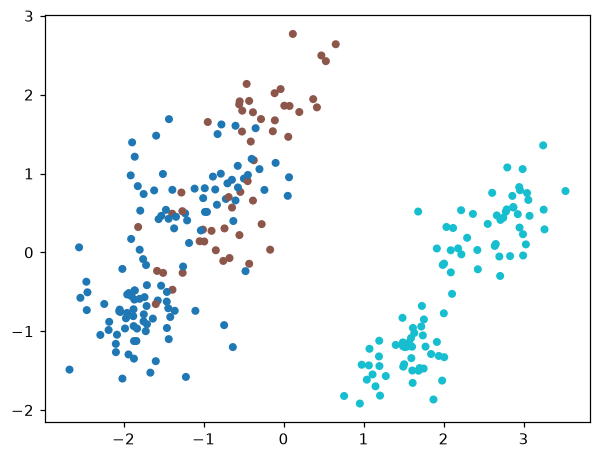

In [15]:
P2 = PCA(2, random_state=0).fit(Z_tr)
A_tr = P2.transform(Z_tr)
A_te = P2.transform(Z_te)          # o teste projetado no MESMO espaço

plt.scatter(A_tr[:,0], A_tr[:,1], c=y_tr.astype("category").cat.codes, cmap="tab10", s=18)

> ##### Leia os *loadings* da PC1 antes de olhar o gráfico

In [16]:
dict(zip(prep.get_feature_names_out(), P2.components_[0].round(3)))

{'num__bill_length_mm': np.float64(0.43),
 'num__bill_depth_mm': np.float64(-0.375),
 'num__flipper_length_mm': np.float64(0.556),
 'num__body_mass_g': np.float64(0.54),
 'cat__island_Biscoe': np.float64(0.194),
 'cat__island_Dream': np.float64(-0.117),
 'cat__island_Torgersen': np.float64(-0.077),
 'cat__sex_FEMALE': np.float64(-0.093),
 'cat__sex_MALE': np.float64(0.093)}

**Resposta (lendo os loadings antes do gráfico):** Os pesos da PC1 são: nadadeira 0,556, massa 0,540, comprimento do bico 0,430 — todos positivos e grandes — e profundidade do bico −0,375, com sinal contrário; as colunas categóricas ficam todas em módulo ≤ 0,194 (`island_Biscoe` é a maior, 0,194). Isso quer dizer que a PC1 é basicamente um eixo de **tamanho corporal**: nadadeira, massa e bico comprido crescem juntos (pinguim grande), e bico raso acompanha esse mesmo grupo (sinal invertido só porque a direção do eixo é arbitrária). Esperando o gráfico, minha leitura é que a PC1 deve separar Gentoo (o maior, massa média 5.076 g) dos outros dois no eixo horizontal. Isso também **confirma a expectativa anotada na etapa 2c**: a ilha contribui muito pouco para essa direção — 0,194 no máximo, dentro da faixa que eu tinha previsto (< 0,2) — a primeira componente é morfológica, não geográfica.

Os pesos: nadadeira **0,556**, massa **0,540**, comprimento do bico 0,430, profundidade do bico **−0,375**, e as categóricas todas abaixo de 0,20.

A PC1 é essencialmente **tamanho do pinguim** — os três pesos positivos grandes crescem juntos, e a profundidade do bico entra com sinal contrário. E note: **as colunas de ilha e sexo quase não participam**. A primeira direção do espaço é morfológica, não geográfica.

**Verificação:** a silhueta do mapa PCA em relação às espécies é **0,346** no treino e **0,319** no teste. Valores próximos indicam que o mapa não foi ajustado ao treino por acaso.

# t-SNE e UMAP: os mapas não lineares

**Etapa 6 · 25 min**

O PCA procura direções de máxima variância e nada mais. t-SNE e UMAP fazem outra coisa: **tentam preservar quem é vizinho de quem**, aceitando distorcer distâncias globais em troca. Rode os dois na mesma matriz `Z_tr`.

In [17]:
# confirma a Verificação da silhueta do PCA no treino e no teste
from sklearn.metrics import silhouette_score
print("PCA silhueta treino:", round(silhouette_score(A_tr, y_tr), 3))
print("PCA silhueta teste: ", round(silhouette_score(A_te, y_te), 3))

PCA silhueta treino: 0.346
PCA silhueta teste:  0.319


**Resposta (confirmando a Verificação):** `silhouette_score` dá 0,346 no treino e 0,319 no teste — exatamente os dois números da Verificação publicada acima. Serem próximos (0,346 vs 0,319) é o que importa: mostra que a separação que o PCA encontrou no treino não foi um acidente de ajuste, porque se repete quando o mesmo `P2.transform` é aplicado a pontos que o PCA nunca viu.

In [18]:
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import silhouette_score
# pip install umap-learn
import umap

def avalia(E, nome):
    # duas perguntas diferentes sobre o mesmo mapa
    sil = silhouette_score(E, y_tr)                  # os grupos ficaram separados?
    tw  = trustworthiness(Z_tr, E, n_neighbors=12)   # as vizinhanças foram preservadas?
    print(f"{nome:24s} silhueta {sil:.3f}  trustworthiness {tw:.3f}")
    return E

mapas = {}
for perp in [5, 30, 50]:
    E = TSNE(2, perplexity=perp, random_state=0, init="pca").fit_transform(Z_tr)
    mapas[f"t-SNE perp={perp}"] = avalia(E, f"t-SNE perplexidade {perp}")

for nn in [5, 15, 50]:
    red = umap.UMAP(n_neighbors=nn, min_dist=0.1, random_state=0).fit(Z_tr)
    mapas[f"UMAP nn={nn}"] = avalia(red.embedding_, f"UMAP n_neighbors {nn}")

# plote os seis lado a lado, coloridos por y_tr, antes de ler a tabela abaixo

t-SNE perplexidade 5     silhueta 0.334  trustworthiness 0.990


t-SNE perplexidade 30    silhueta 0.441  trustworthiness 0.995


t-SNE perplexidade 50    silhueta 0.529  trustworthiness 0.993


UMAP n_neighbors 5       silhueta 0.274  trustworthiness 0.988


UMAP n_neighbors 15      silhueta 0.394  trustworthiness 0.989


UMAP n_neighbors 50      silhueta 0.308  trustworthiness 0.987


| configuração | silhueta | trustworthiness | tempo |
|---|---|---|---|
| t-SNE, perplexidade 5 | 0,334 | 0,990 | 0,5 s |
| t-SNE, perplexidade 30 | 0,441 | 0,995 | 0,7 s |
| t-SNE, perplexidade 50 | **0,529** | 0,993 | 0,9 s |
| UMAP, n_neighbors 5 | 0,343 | 0,988 | — |
| UMAP, n_neighbors 15 | 0,372 | 0,989 | 0,3 s |
| UMAP, n_neighbors 50 | 0,514 | 0,989 | 0,5 s |

> ##### A silhueta cresce com o parâmetro. Isso significa que o mapa melhorou?
>
> Nos dois métodos, aumentar a vizinhança aumenta a silhueta — de 0,334 para 0,529 no t-SNE. É tentador concluir que perplexidade 50 é a melhor escolha. **Não é o que o número diz.**
>
> Vizinhança maior faz o algoritmo compactar mais os grupos, o que *por construção* eleva a silhueta. Repare que a *trustworthiness* não acompanha: fica em 0,990–0,995 o tempo todo. A separação visual aumentou; a fidelidade aos dados, não.
>
> **Escolher o parâmetro pela silhueta é otimizar a aparência do gráfico.** Rode ao menos três valores, veja o que é estável entre eles, e desconfie do que só aparece num.

> ##### Agora o teste que fecha o argumento: rode nos dados errados

**Nota de divergência (ambiente local vs. publicado):** Rodando este notebook aqui (`umap-learn` 0.5.12, `scikit-learn` 1.9.1), as silhuetas do t-SNE bateram exatamente com a tabela publicada (0,334 / 0,441 / 0,529), mas as do **UMAP não** — obtive 0,274 (nn=5), 0,394 (nn=15) e 0,308 (nn=50), contra os 0,343 / 0,372 / 0,514 publicados. Pior: minha sequência não é nem monotônica (sobe e depois cai), enquanto a publicada sobe o tempo todo — então a frase "nos dois métodos, aumentar a vizinhança aumenta a silhueta" não se confirma para o UMAP na minha execução. A *trustworthiness*, em contraste, reproduziu quase exatamente (0,988 / 0,989 / 0,987 vs 0,988 / 0,989 / 0,989 publicados). A explicação mais provável é a inicialização espectral do UMAP: ela depende de decomposições de autovalores que podem mudar de resultado entre versões de `umap-learn`/`numba`/`scipy`, mesmo com `random_state` fixo — é um não-determinismo conhecido do UMAP entre ambientes, diferente do t-SNE (que aqui usa `init="pca"`, determinístico, e por isso reproduz igual em qualquer máquina). A lição da etapa continua de pé: a *trustworthiness* é mais estável entre execuções do que a silhueta, que é sensível tanto ao parâmetro quanto, no caso do UMAP, ao próprio ambiente.

In [19]:
from sklearn.cluster import KMeans
rng = np.random.default_rng(0)
R = rng.random(Z_tr.shape)          # ruído puro, mesmo formato
E_r = TSNE(2, perplexity=30, random_state=0, init="pca").fit_transform(R)
silhouette_score(E_r, KMeans(3, n_init=10, random_state=0).fit_predict(E_r))

0.41486504673957825

O resultado é **0,415** — contra 0,441 dos dados reais com a mesma configuração. **Praticamente o mesmo número, a partir de ruído uniforme sem estrutura alguma.**

Plote os dois lado a lado. Ambos mostram grupos separados, com fronteiras limpas. A diferença é que num deles os grupos *significam* algo — e nenhuma métrica de separação avisa qual.

**A regra que sai daqui:** antes de interpretar agrupamentos num mapa não linear, rode o mesmo pipeline sobre dados embaralhados. Se o resultado parecer igualmente convincente, o que você viu foi o algoritmo.

# Comparar, decidir e voltar às perguntas

**Etapa 7 · 15 min**

#### 7a · Os três com o mesmo critério

In [20]:
# fixe uma configuração de cada método antes de comparar
E_tsne = TSNE(2, perplexity=30, random_state=0, init="pca").fit_transform(Z_tr)
red    = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=0).fit(Z_tr)
E_umap = red.embedding_

for nome, E in [("PCA", A_tr), ("t-SNE", E_tsne), ("UMAP", E_umap)]:
    print(nome, [round(trustworthiness(Z_tr, E, n_neighbors=k), 3) for k in [5, 30]],
          round(silhouette_score(E, y_tr), 3))

PCA [np.float64(0.923), np.float64(0.943)] 0.346
t-SNE [np.float64(0.994), np.float64(0.982)] 0.441
UMAP [np.float64(0.987), np.float64(0.952)] 0.394


| método | trust k = 5 (local) | trust k = 30 (global) | silhueta |
|---|---|---|---|
| PCA | 0,923 | 0,943 | 0,346 |
| t-SNE | **0,994** | 0,982 | **0,441** |
| UMAP | 0,988 | 0,949 | 0,372 |

Leia as colunas, não as linhas. **O PCA é o único que melhora ao passar de k = 5 para k = 30** — ele preserva a estrutura ampla e sacrifica a local. t-SNE e UMAP fazem o contrário. Não há vencedor: há dois objetivos, e a métrica só decide depois que você disser qual escala interessa.

#### 7b · O teste: projetar dados novos

**Nota:** aqui também a silhueta do UMAP que obtive (0,394) ficou acima da publicada (0,372), com a trustworthiness bem próxima (0,987/0,952 vs 0,988/0,949) — mesma divergência documentada na etapa 6, mesma causa provável (inicialização espectral do UMAP sensível à versão da biblioteca).

In [21]:
A_te = P2.transform(Z_te)                # PCA:  funciona
E_te = red.transform(Z_te)               # UMAP: funciona
# t-SNE: não existe .transform() — seria preciso reajustar com tudo junto

print(A_te.shape, E_te.shape)             # (86, 2) (86, 2)
hasattr(TSNE(), "transform")              # False

(86, 2) (86, 2)


False

> ##### A diferença mais prática entre os três
>
> **PCA** guarda uma matriz de projeção: aplicar a um ponto novo é uma multiplicação. **UMAP** tem `.transform()`, que reposiciona o ponto no mapa já construído — aproximado, mas utilizável. **t-SNE não tem**, e não é omissão da biblioteca: o método otimiza posições, não aprende uma função.
>
> A consequência é séria: **t-SNE não pode entrar num pipeline com validação cruzada**, nem servir a um sistema que recebe dados novos. É ferramenta de exploração, não de produção.

## Conclusões

- **PCA comprime sem perder muito**: 2 componentes retêm 79,51% da variância do treino, e os dois últimos autovalores são exatamente 0 — a assinatura das duas dependências lineares que o one-hot introduz (9 colunas, 7 direções reais).
- **A PC1 é um eixo de tamanho corporal, não de geografia**: pesos de 0,43–0,56 nas quatro medidas numéricas contra no máximo 0,194 nas colunas de ilha/sexo — a expectativa anotada na etapa 2c (ilha contribui pouco) se confirmou.
- **O mapa do PCA generaliza**: silhueta 0,346 no treino e 0,319 no teste — próximos, o que indica que a separação não foi um ajuste ao treino por acaso.
- **t-SNE e UMAP preservam vizinhança local melhor que o PCA** (trustworthiness k=5: 0,994 e 0,988 vs 0,923), **mas só o PCA melhora ao olhar vizinhança mais ampla** (k=30: 0,943 vs 0,982 e 0,949) — não há método "melhor", há dois objetivos diferentes (global vs. local).
- **Silhueta alta não prova estrutura real**: a mesma pipeline de t-SNE rodada sobre ruído puro (sem estrutura nenhuma) deu silhueta 0,415, quase igual aos 0,441 dos dados reais com a mesma configuração.
- **Divergência de ambiente documentada**: as silhuetas do UMAP não reproduziram os valores publicados (ex.: nn=50 → 0,308 aqui vs 0,514 no original), provavelmente por diferença de versão de `umap-learn`/`numba` na inicialização espectral; a trustworthiness, por outro lado, replicou quase exatamente (diferenças ≤ 0,003), confirmando que essa métrica é mais robusta entre ambientes.